# Figure 5

In [10]:
from riskhistory.format import rcParams
from riskhistory.data import (
    load_loo_comparison,
    load_robustness_loo,
    load_pupilacceptmodel_historyeffect_by_pupilbin,
    load_pupilacceptmodel_pupilbin_contrast,
    load_ddmppcbehavior_pupilaccept_fixed_effects,
    load_ddmppcbehavior_pupilaccept_comparison_fixed_effects,
    DATASET_LABELS,
)
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

DATASETS = ["equalIndifference", "equalRange", "sheng2020"]

### Helper functions

In [11]:
def sig_stars(p):
    if p < 0.001:
        return "***"
    if p < 0.01:
        return "**"
    if p < 0.05:
        return "*"
    return "n.s."


def add_significance_bracket(ax, x1, x2, y, h, p):
    ax.plot([x1, x1, x2, x2], [y, y + h, y + h, y], color="black", linewidth=1.2)
    ax.text((x1 + x2) / 2, y + h, sig_stars(p), ha="center", va="bottom")


def style_axis(ax, col=None, ylabel=None, xlabel=None, xlabel_col=1):
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    if col == 0 and ylabel:
        ax.set_ylabel(ylabel)
    if col == xlabel_col and xlabel:
        ax.set_xlabel(xlabel)

def compute_elpd_vs_baseline(dataset, baseline_model, model_order):
    loo = (load_loo_comparison(dataset, group_name="arousal")
           .set_index("model")["elpd_loo"])
    baseline_elpd = loo[baseline_model]
    return [loo[m] - baseline_elpd for m, _ in model_order]

def compute_elpd_robustness_vs_baseline(dataset, baseline_model, model_order,
                                        column="elpd_loo_reliable_only"):
    loo = load_robustness_loo(dataset, group_name = "arousal").set_index("model")[column]

    diffs = []
    for model_id, _ in model_order:
        diffs.append(loo[model_id] - loo[baseline_model])
    return diffs

### Figure 5
Row A: choice-history effect on acceptance probability, by pupil bin (median split within subject). Row B: `choice_prev1:pupil` fixed-effect estimate (log-odds) recovered from DDM-PPC simulated data, for a starting-point/drift choice-history baseline (no pupil interaction in the DDM itself) and its pupil-interaction counterpart, for each mechanism. Brackets show whether the estimate differs significantly between each baseline and its xPupil counterpart.

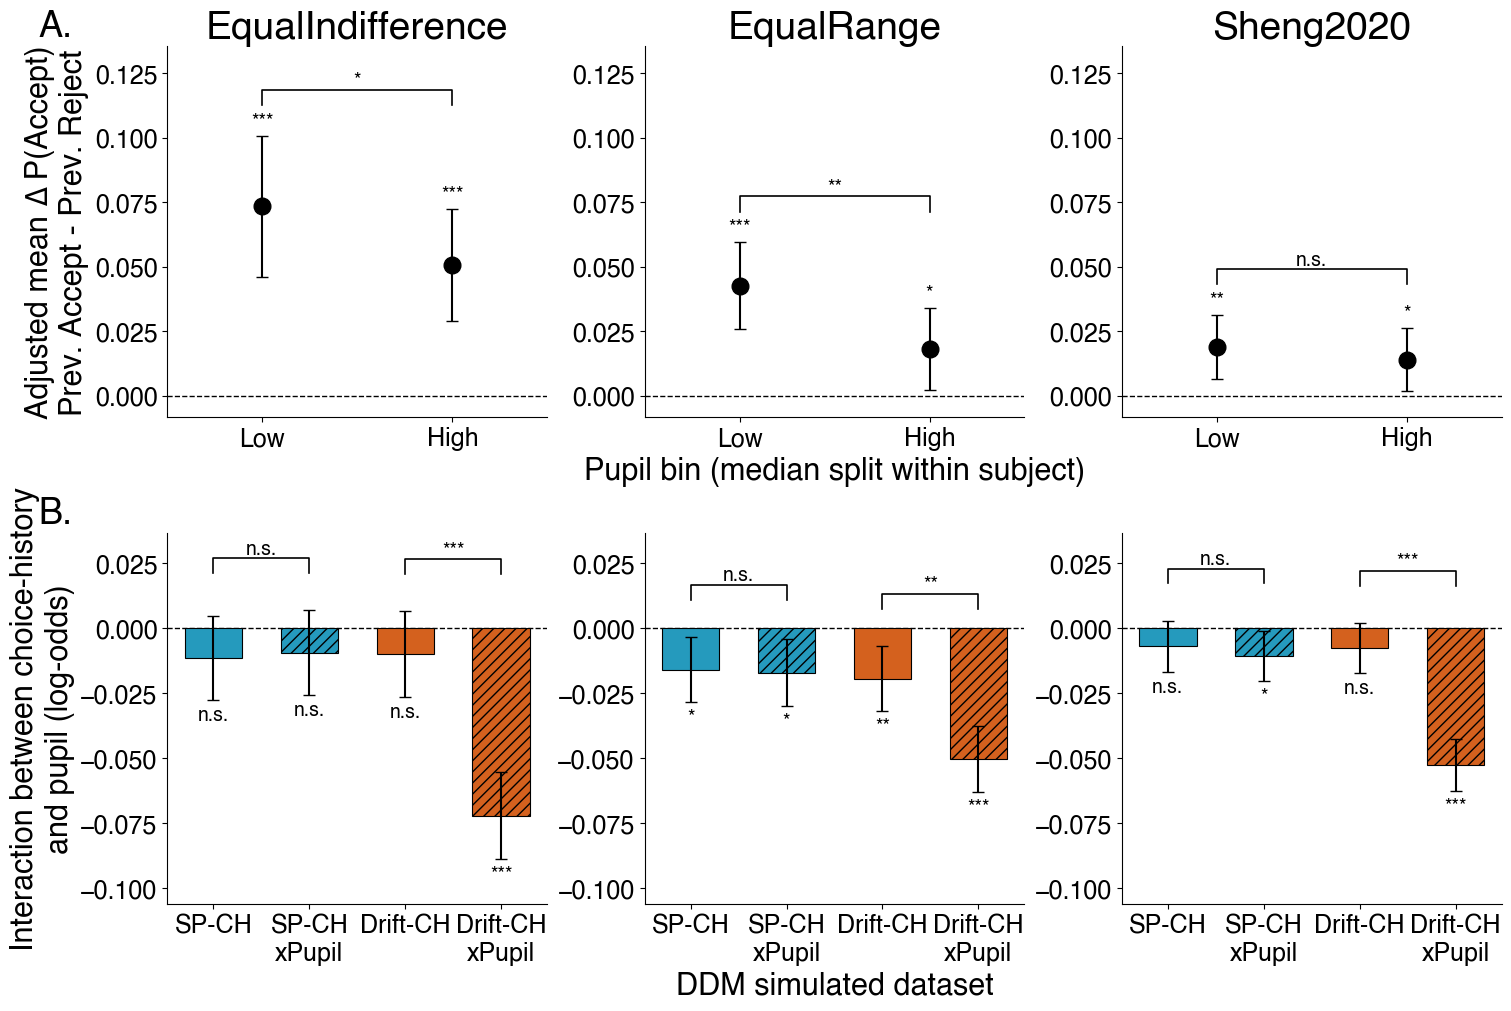

In [18]:
# --- Row A data: choice-history effect by pupil bin ---
PUPIL_BIN_ORDER = ["Low", "High"]
HISTORYEFFECT_COLOR = "black"

historyeffect_by_pupilbin = load_pupilacceptmodel_historyeffect_by_pupilbin()
pupilbin_contrast = load_pupilacceptmodel_pupilbin_contrast()

hist_los = historyeffect_by_pupilbin["asymp.LCL"].values
hist_his = historyeffect_by_pupilbin["asymp.UCL"].values
hist_range = hist_his.max() - hist_los.min()
HISTORYEFFECT_YLIM = (hist_los.min() - 0.1 * hist_range, hist_his.max() + 0.35 * hist_range)

# --- Row B data: choice_prev1:pupil interaction, DDM-PPC pupil-accept models ---
# (x-label, ddm_model, term name in ddm_fixed_effects)
CHOICE_PUPIL_CATEGORIES = [
    ("SP-CH",           "HDDM_Base_Lag1-stp_Pupil",         "real_choice_prev1:pupil"),
    ("SP-CH\nxPupil",   "HDDM_Base_Lag1-stp_Pupil_stp",     "real_choice_prev1:pupil"),
    ("Drift-CH",         "HDDM_Base_Lag1-drift_Pupil",       "real_choice_prev1:pupil"),
    ("Drift-CH\nxPupil", "HDDM_Base_Lag1-drift_Pupil_drift", "real_choice_prev1:pupil"),
]

# Color codes the mechanism (SP vs. Drift); hatch codes whether the DDM
# itself has a pupil interaction (CH-only vs. xPupil).
SP_COLOR = "#259ABD"
DRIFT_COLOR = "#D4611E"
CHOICE_PUPIL_COLORS = [SP_COLOR, SP_COLOR, DRIFT_COLOR, DRIFT_COLOR]
CHOICE_PUPIL_HATCHES = ["", "///", "", "///"]

# (index of no-pupil baseline, index of its xPupil counterpart, model_pair in
# the comparison CSV, term for the model_type interaction)
COMPARISON_PAIRS = [
    (0, 1, "stp",   "real_choice_prev1:pupil:model_typepupil"),
    (2, 3, "drift", "real_choice_prev1:pupil:model_typepupil"),
]

ddm_fixed_effects = load_ddmppcbehavior_pupilaccept_fixed_effects()
comparison_fixed_effects = load_ddmppcbehavior_pupilaccept_comparison_fixed_effects()


def get_choice_pupil_row(dataset, ddm_model, term):
    df = ddm_fixed_effects
    row = df[(df["dataset"] == dataset) & (df["ddm_model"] == ddm_model) & (df["term"] == term)]
    return row.iloc[0]


def get_comparison_p(dataset, model_pair, term):
    df = comparison_fixed_effects
    row = df[(df["dataset"] == dataset) & (df["model_pair"] == model_pair) & (df["term"] == term)]
    return row.iloc[0]["p_adj_bh"]


choice_pupil_x_labels = [label for label, _, _ in CHOICE_PUPIL_CATEGORIES]
choice_pupil_x_pos = np.arange(len(CHOICE_PUPIL_CATEGORIES))

choice_pupil_data = {}
for ds in DATASETS:
    estimates, los, his, pvals = [], [], [], []
    for _, ddm_model, term in CHOICE_PUPIL_CATEGORIES:
        row = get_choice_pupil_row(ds, ddm_model, term)
        estimates.append(row["estimate"])
        los.append(row["conf.low"])
        his.append(row["conf.high"])
        pvals.append(row["p_adj_bh"])
    choice_pupil_data[ds] = dict(estimate=np.array(estimates), lo=np.array(los),
                                 hi=np.array(his), pval=np.array(pvals))

choice_pupil_all_lo = np.concatenate([d["lo"] for d in choice_pupil_data.values()])
choice_pupil_all_hi = np.concatenate([d["hi"] for d in choice_pupil_data.values()])
choice_pupil_data_range = choice_pupil_all_hi.max() - choice_pupil_all_lo.min()

STAR_MARGIN = 0.08 * choice_pupil_data_range      # space for each bar's own significance stars, below its lower CI
BRACKET_MARGIN = 0.15 * choice_pupil_data_range   # gap above each bar's upper CI before the comparison bracket
BRACKET_H = 0.06 * choice_pupil_data_range

CHOICE_PUPIL_YLIM = (choice_pupil_all_lo.min() - STAR_MARGIN - 0.1 * choice_pupil_data_range,
                     choice_pupil_all_hi.max() + BRACKET_MARGIN + BRACKET_H + 0.1 * choice_pupil_data_range)

fig, axes = plt.subplots(nrows=2, ncols=3, figsize=(15, 10), layout="constrained")

for col, ds in enumerate(DATASETS):
    # --- Row A: choice-history effect by pupil bin ---
    ax = axes[0, col]
    x_pos = np.arange(len(PUPIL_BIN_ORDER))
    ds_hist = (
        historyeffect_by_pupilbin[historyeffect_by_pupilbin["dataset"] == ds]
        .set_index("pupil_bin").loc[PUPIL_BIN_ORDER]
    )
    ds_contrast_p = pupilbin_contrast.loc[pupilbin_contrast["dataset"] == ds, "p_adj_bh"].iloc[0]

    means = ds_hist["historyeffect"].values
    los   = ds_hist["asymp.LCL"].values
    his   = ds_hist["asymp.UCL"].values
    yerr  = [means - los, his - means]

    ax.errorbar(x_pos, means, yerr=yerr, fmt="o", color=HISTORYEFFECT_COLOR,
               markersize=12, capsize=4, elinewidth=1.5, zorder=2)
    ax.axhline(0, color="black", linewidth=1, linestyle="--", zorder=1)

    for x, y_top, p in zip(x_pos, his, ds_hist["p_adj_bh"]):
        ax.annotate(sig_stars(p), xy=(x, y_top), xytext=(0, 4),
                   textcoords="offset points", ha="center", va="bottom")

    bracket_y = his.max() + 0.12 * hist_range
    bracket_h = 0.06 * hist_range
    add_significance_bracket(ax, x_pos[0], x_pos[1], bracket_y, bracket_h, ds_contrast_p)

    ax.set_xlim(-0.5, len(PUPIL_BIN_ORDER) - 0.5)
    ax.set_ylim(*HISTORYEFFECT_YLIM)
    ax.set_xticks(x_pos)
    ax.set_xticklabels(PUPIL_BIN_ORDER)
    ax.set_title(DATASET_LABELS.get(ds, ds))
    style_axis(ax, col, ylabel="Adjusted mean ∆ P(Accept)\nPrev. Accept - Prev. Reject",
              xlabel="Pupil bin (median split within subject)")

    # --- Row B: choice_prev1:pupil interaction, DDM-PPC pupil-accept models ---
    ax = axes[1, col]
    d = choice_pupil_data[ds]
    yerr = [d["estimate"] - d["lo"], d["hi"] - d["estimate"]]

    ax.bar(choice_pupil_x_pos, d["estimate"], yerr=yerr, color=CHOICE_PUPIL_COLORS,
          hatch=CHOICE_PUPIL_HATCHES, edgecolor="black", linewidth=0.8, width=0.6,
          capsize=4, error_kw=dict(elinewidth=1.5), zorder=2)
    ax.axhline(0, color="black", linewidth=1, linestyle="--", zorder=1)

    for x, y_bottom, p in zip(choice_pupil_x_pos, d["lo"], d["pval"]):
        ax.annotate(sig_stars(p), xy=(x, y_bottom), xytext=(0, -4),
                   textcoords="offset points", ha="center", va="top")

    for i1, i2, model_pair, term in COMPARISON_PAIRS:
        p_comparison = get_comparison_p(ds, model_pair, term)
        pair_hi = max(d["hi"][i1], d["hi"][i2])
        bracket_y = pair_hi + BRACKET_MARGIN
        add_significance_bracket(ax, choice_pupil_x_pos[i1], choice_pupil_x_pos[i2], bracket_y, BRACKET_H, p_comparison)

    ax.set_xticks(choice_pupil_x_pos)
    ax.set_xticklabels(choice_pupil_x_labels)
    ax.set_ylim(*CHOICE_PUPIL_YLIM)
    if col == 1:
        ax.set_xlabel("DDM simulated dataset")
    style_axis(ax, col, ylabel="Interaction between choice-history\nand pupil (log-odds)")

# Row labels, placed just outside the top-left corner of each row's leftmost
# panel (same convention as figure1.ipynb's "A."/"B."/"C.")
axes[0, 0].text(-0.25, 1.1, "A.", transform=axes[0, 0].transAxes,
               fontsize=26, fontweight="bold", va="top", ha="right")
axes[1, 0].text(-0.25, 1.1, "B.", transform=axes[1, 0].transAxes,
               fontsize=26, fontweight="bold", va="top", ha="right")

fig.savefig("saved/figure5.svg", dpi=300, bbox_inches="tight")
plt.show()

### ELPD robustness checks

In [13]:
ELPD_MODEL_ORDER_robust = [
    ("HDDM_Base_Lag1-drift_Pupil", "Drift CH"),
    ("HDDM_Base_Lag1-stp_Pupil", "SP CH"),
]
elpd_vs_baseline_robust = {}
elpd_labels_robust = [label for _, label in ELPD_MODEL_ORDER_robust]
for ds in DATASETS:
    elpd_vs_baseline_robust[ds] = compute_elpd_vs_baseline(ds, "HDDM_Base_Pupil", ELPD_MODEL_ORDER_robust)
    print(f"\n{ds}")
    robust_diffs = compute_elpd_robustness_vs_baseline(ds, "HDDM_Base_Pupil", ELPD_MODEL_ORDER_robust)
    summary = pd.DataFrame({
        "model": elpd_labels_robust,
        "delta_elpd": elpd_vs_baseline_robust[ds],
        "delta_elpd_robust": robust_diffs,
    })
    print(summary.to_string(index=False))


equalIndifference
   model  delta_elpd  delta_elpd_robust
Drift CH   61.108450          59.387890
   SP CH   71.268302          59.426419

equalRange
   model  delta_elpd  delta_elpd_robust
Drift CH   10.146366          12.372202
   SP CH   24.726943          23.312064

sheng2020
   model  delta_elpd  delta_elpd_robust
Drift CH   20.417033          20.798487
   SP CH  106.273388          87.388347


In [14]:
ELPD_MODEL_ORDER_robust = [
    ("HDDM_Base_Lag1-drift_Pupil_drift", "PupilxDrift CH"),
]
elpd_vs_baseline_robust = {}
elpd_labels_robust = [label for _, label in ELPD_MODEL_ORDER_robust]
for ds in DATASETS:
    elpd_vs_baseline_robust[ds] = compute_elpd_vs_baseline(ds, "HDDM_Base_Lag1-drift_Pupil", ELPD_MODEL_ORDER_robust)
    print(f"\n{ds}")
    robust_diffs = compute_elpd_robustness_vs_baseline(ds, "HDDM_Base_Lag1-drift_Pupil", ELPD_MODEL_ORDER_robust)
    summary = pd.DataFrame({
        "model": elpd_labels_robust,
        "delta_elpd": elpd_vs_baseline_robust[ds],
        "delta_elpd_robust": robust_diffs,
    })
    print(summary.to_string(index=False))


equalIndifference
         model  delta_elpd  delta_elpd_robust
PupilxDrift CH   17.565048          19.931099

equalRange
         model  delta_elpd  delta_elpd_robust
PupilxDrift CH   -0.655087          -1.849813

sheng2020
         model  delta_elpd  delta_elpd_robust
PupilxDrift CH   13.694954          12.160898


In [15]:
ELPD_MODEL_ORDER_robust = [
    ("HDDM_Base_Lag1-stp_Pupil_stp", "PupilxStp CH"),
]
elpd_vs_baseline_robust = {}
elpd_labels_robust = [label for _, label in ELPD_MODEL_ORDER_robust]
for ds in DATASETS:
    elpd_vs_baseline_robust[ds] = compute_elpd_vs_baseline(ds, "HDDM_Base_Lag1-stp_Pupil", ELPD_MODEL_ORDER_robust)
    print(f"\n{ds}")
    robust_diffs = compute_elpd_robustness_vs_baseline(ds, "HDDM_Base_Lag1-stp_Pupil", ELPD_MODEL_ORDER_robust)
    summary = pd.DataFrame({
        "model": elpd_labels_robust,
        "delta_elpd": elpd_vs_baseline_robust[ds],
        "delta_elpd_robust": robust_diffs,
    })
    print(summary.to_string(index=False))


equalIndifference
       model  delta_elpd  delta_elpd_robust
PupilxStp CH     4.67581          11.789109

equalRange
       model  delta_elpd  delta_elpd_robust
PupilxStp CH    1.734182           3.038749

sheng2020
       model  delta_elpd  delta_elpd_robust
PupilxStp CH    1.651307          -1.785917
